# 📘 Построение Baseline-модели
В этом уроке мы:

* разберём подход к разбиению временных данных;
* построим baseline-модель на CatBoost;
* разберём ключевые метрики;
* подготовим почву для улучшений;
* выполним мини-проект (домашка по доставке еды).

## 📥 Загружаем данные

In [1]:
import os

FOLDER = 'content'

# Проверка наличия папки и создание по необходимости
os.makedirs(FOLDER, exist_ok=True)

In [2]:
import requests

URL = "https://raw.githubusercontent.com/totiela/stepik_simulator_ds/main/lessons/lesson_4_1/4_1_churn_dataset.csv"
FOLDER = 'content'
PATH = os.path.join(FOLDER, '4_1_churn_dataset.csv')

# Проверка наличия файла и скачивание по необходимости
if not os.path.exists(PATH):
    r = requests.get(URL)
    with open(PATH, 'wb') as f:
        f.write(r.content)
    print('Файл скачан:', PATH)
else:
    print('Файл уже скачан')

Файл уже скачан


In [3]:
# Загружаем данные

import pandas as pd

# url = "https://raw.githubusercontent.com/totiela/stepik_simulator_ds/main/lessons/lesson_4_1/4_1_churn_dataset.csv"
df  = pd.read_csv('content/4_1_churn_dataset.csv')

df.sample(3)

,snapshot_month,client_id,n_contacts,n_success_calls,n_fail_calls,n_sms,n_emails,bal_min_30d,bal_max_30d,bal_avg_30d,amt_sum_30d,risk_score,engagement_score,days_since_last_txn,is_term_deposit,is_credit_active,is_mobile_app_user,is_salary_client,target_churn_next
56998,2025-09-30,C018928,0,0,0,2,2,7662.045363,14103.109969,10977.588307,3680.491176,30.120020,61.676204,40,0,0,1,1,0
9195,2025-06-30,C004575,2,0,2,2,2,4849.965046,7054.611516,5605.877916,7893.118440,59.410224,47.968439,65,0,1,1,1,0
77169,2025-09-30,C011964,2,0,2,2,1,12338.293922,23198.316738,15642.225035,7156.811444,18.255951,68.023068,49,0,0,1,1,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 19 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   snapshot_month       100000 non-null  str    
 1   client_id            100000 non-null  str    
 2   n_contacts           100000 non-null  int64  
 3   n_success_calls      100000 non-null  int64  
 4   n_fail_calls         100000 non-null  int64  
 5   n_sms                100000 non-null  int64  
 6   n_emails             100000 non-null  int64  
 7   bal_min_30d          100000 non-null  float64
 8   bal_max_30d          100000 non-null  float64
 9   bal_avg_30d          100000 non-null  float64
 10  amt_sum_30d          100000 non-null  float64
 11  risk_score           100000 non-null  float64
 12  engagement_score     100000 non-null  float64
 13  days_since_last_txn  100000 non-null  int64  
 14  is_term_deposit      100000 non-null  int64  
 15  is_credit_active     100000 n

In [5]:
# для удобства распишем списки перед обучением

target = 'target_churn_next'
cols_to_drop = ['snapshot_month',	'client_id', 'target_churn_next']

In [6]:
# from sklearn.preprocessing import train_test_split

# X = df.drop(cols_to_drop, axis=1)
# y = df[target]

# X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

## 📅 Разделяем данные **по времени**, а не случайно

При задачах, связанных с прогнозированием будущего, **нельзя использовать случайное разбиение**.
Мы должны **имитировать реальное будущее**: сначала модель учится на старых данных -> проверяется на более свежих.

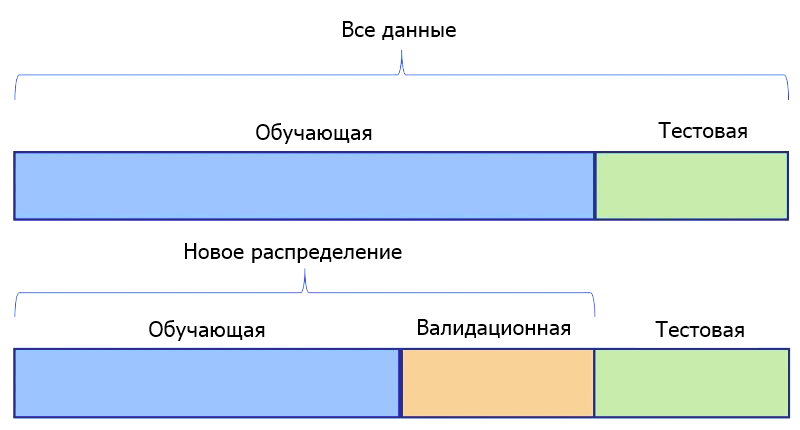

In [7]:
#  Приводим колонку к типу datetime
df['snapshot_month'] = pd.to_datetime(df['snapshot_month'])

# Берём "точки разреза" по времени
# 60-й и 80-й процентили распределения даты
q60 = df['snapshot_month'].quantile(0.60)
q80 = df['snapshot_month'].quantile(0.80)

# Разделяем данные по временным интервалам

# Train: самое раннее  → 60%
train_df = df[df['snapshot_month'] <= q60].copy()

# Validation: 60% → 80%
val_df = df[(df['snapshot_month'] > q60) & (df['snapshot_month'] <= q80)].copy()

# OOT (Out-of-Time): последние 20%
# Это самые свежие данные -> честная проверка того,
# как модель работает на будущем, которого она "не видела".
oot_df = df[df['snapshot_month'] > q80].copy()

# Проверим результаты
print("Разделение по квантилям snapshot_month:")
print(f"- Train: {train_df.shape[0]} строк")
print(f"- Val:   {val_df.shape[0]} строк")
print(f"- OOT:   {oot_df.shape[0]} строк")


Разделение по квантилям snapshot_month:
- Train: 60392 строк
- Val:   19650 строк
- OOT:   19958 строк


In [8]:
q60, q80

(Timestamp('2025-06-30 00:00:00'), Timestamp('2025-08-31 00:00:00'))

## 🚀🐈 Бейзлайн-модель: CatBoost

Для первой рабочей модели (**baseline**) мы возьмём одно из самых сильных решений для табличных данных — **градиентный бустинг CatBoost от Yandex**.

Почему CatBoost отлично подходит под бейзлайн?

*  почти не требует подготовки признаков
*  умеет работать с категориальными фичами **без One-Hot Encoding**
*  стабилен, быстро обучается
*  часто даёт топ-качество «из коробки»

> 💡 Можно использовать и LightGBM / XGBoost — это тоже отличные бустинги.
> Но если вы **всё равно планируете** модель на бустинге, то делать бейзлайн на логистической регрессии или дереве — бессмысленно.
> Исключение — если по условиям задачи доступен **только линейный алгоритм** -> тогда бейзлайн берём логрег, но придётся сильнее готовить признаки.

In [9]:
# # 🐈 Устанавливаем CatBoost
# !pip install -q catboost

## 📦 Подготовка данных для CatBoost

CatBoost может обучаться на обычных `DataFrame`,
но рекомендуется использовать специальный класс **`Pool`** — в него можно передавать:

* признаки (X),
* целевую переменную (y),
* список категориальных колонок,
* веса объектов,
* и многое другое.

Документация:
[https://catboost.ai/docs/en/concepts/python-reference_pool](https://catboost.ai/docs/en/concepts/python-reference_pool)

In [10]:
# Создадим три пула: для train, val и OOT

from catboost import Pool

# Формируем матрицы признаков и целевые переменные
X_train = train_df.drop(cols_to_drop, axis=1)
y_train = train_df[target]

X_val = val_df.drop(cols_to_drop, axis=1)
y_val = val_df[target]

X_oot = oot_df.drop(cols_to_drop, axis=1)
y_oot = oot_df[target]

# Создаем Pool-объекты
train_pool = Pool(X_train, label=y_train)
val_pool   = Pool(X_val,  label=y_val)
oot_pool   = Pool(X_oot,  label=y_oot)

##🎯 Выбор метрик и базовая модель CatBoost
 <p> Перед стартом моделирования важно заранее определить <strong>основные метрики качества</strong> — именно они покажут, корректно ли обучается модель и сможет ли она принести бизнес-ценность. </p> <p> Так как у нас <strong>бинарная классификация</strong>, оптимальной основной метрикой будет <code>ROC AUC</code>. Она: <ul> <li>устойчива к несбалансированным выборкам;</li> <li>не зависит от выбранного порога;</li> <li>отражает способность модели ранжировать объекты.</li> </ul> Это именно то, что нам нужно для скоринговых задач. </p> <p> CatBoost обладает большим числом параметров — все они описаны <a href="https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier">в официальной документации</a>. Ниже — базовая конфигурация, которая работает удивительно стабильно. </p>

In [11]:
# Обучаем базовый CatBoost

from catboost import CatBoostClassifier

cb_baseline = CatBoostClassifier(
    iterations=1000,
    depth=6,
    loss_function='Logloss',
    eval_metric='AUC',
    early_stopping_rounds=100,
    verbose=False
)

cb_baseline.fit(
    train_pool,
    eval_set=val_pool,
    use_best_model=True,
    # plot=True # если не в google colab - будет работать - крутая штука
)

CatBoostClassifier(depth=6, early_stopping_rounds=100, eval_metric='AUC', iterations=1000, loss_function='Logloss', verbose=False)

In [12]:
# посмотреть все параметры модели
cb_baseline.get_all_params()

{'nan_mode': 'Min',
 'eval_metric': 'AUC',
 'iterations': 1000,
 'sampling_frequency': 'PerTree',
 'leaf_estimation_method': 'Newton',
 'od_pval': 0,
 'random_score_type': 'NormalWithModelSizeDecrease',
 'grow_policy': 'SymmetricTree',
 'penalties_coefficient': 1,
 'boosting_type': 'Plain',
 'model_shrink_mode': 'Constant',
 'feature_border_type': 'GreedyLogSum',
 'bayesian_matrix_reg': 0.10000000149011612,
 'eval_fraction': 0,
 'force_unit_auto_pair_weights': False,
 'l2_leaf_reg': 3,
 'random_strength': 1,
 'od_type': 'Iter',
 'rsm': 1,
 'boost_from_average': False,
 'model_size_reg': 0.5,
 'pool_metainfo_options': {'tags': {}},
 'subsample': 0.800000011920929,
 'use_best_model': True,
 'od_wait': 100,
 'class_names': [0, 1],
 'random_seed': 0,
 'depth': 6,
 'posterior_sampling': False,
 'border_count': 254,
 'classes_count': 0,
 'auto_class_weights': 'None',
 'sparse_features_conflict_fraction': 0,
 'leaf_estimation_backtracking': 'AnyImprovement',
 'best_model_min_trees': 1,
 'mode

In [13]:
# Предикты и ROC AUC
from sklearn.metrics import roc_auc_score

# Получаем вероятности положительного класса
# Для CatBoost: predict_proba возвращает вероятности двух классов
train_proba = cb_baseline.predict_proba(train_pool)[:, 1]
val_proba   = cb_baseline.predict_proba(val_pool)[:, 1]
oot_proba   = cb_baseline.predict_proba(oot_pool)[:, 1]

# Извлечем истинные значения
y_train = train_pool.get_label()
y_val   = val_pool.get_label()
y_oot   = oot_pool.get_label()

# Рассчитаем ROC AUC
roc_train = roc_auc_score(y_train, train_proba)
roc_val   = roc_auc_score(y_val,   val_proba)
roc_oot   = roc_auc_score(y_oot,   oot_proba)

# Выводим результаты
print("ROC AUC:")
print(f"  training: {roc_train:.6f}" if roc_train is not None else "  training: недоступно")
print(f"  validation: {roc_val:.6f}" if roc_val is not None else "  validation: недоступно")
print(f"  oot: {roc_oot:.6f}" if roc_oot is not None else "  oot: недоступно")

ROC AUC:
  training: 0.877974
  validation: 0.849494
  oot: 0.843624


<h3>📌 Итог</h3> <p> Мы получили <strong>стабильный baseline</strong> — опорную точку, от которой будем улучшать модель дальше. Такие результаты важны: если модель на этом этапе “здорово” себя ведёт на train/val/OOT, значит можно безопасно переходить к тюнингу признаков и гиперпараметров. </p>

## 🧪 Задание для закрепления

Домашняя работа — Прогноз времени доставки еды

В этом задании ты познакомишься с реальным датасетом и пройдёшь путь от постановки задачи до первой модели машинного обучения.  



**Данные**

Каждая строка — заказ доставки еды за 2025 год.
В данных есть характеристики заказа, курьера, ресторана, погоды и дорожной ситуации.

**Основные признаки:**

* `order_datetime` — время заказа (с января по октябрь 2025).
* `distance_km`, `items_count`, `subtotal`, `prep_time_min` — особенности заказа.
* `courier_experience_yrs`, `courier_rating`, `restaurant_rating`.
* `weather`, `traffic`, `area`, `temperature_c`, `holiday`, `surge_coef`.
* **`delivery_time_min`** — целевая переменная (время доставки в минутах).



In [14]:
URL = "https://raw.githubusercontent.com/totiela/stepik_simulator_ds/main/lessons/lesson_4_1/4_1_homework_dataset.csv"
FOLDER = 'content'
PATH = os.path.join(FOLDER, '4_1_homework_dataset.csv')

# Проверка наличия файла и скачивание по необходимости
if not os.path.exists(PATH):
    r = requests.get(URL)
    with open(PATH, 'wb') as f:
        f.write(r.content)
    print('Файл скачан:', PATH)
else:
    print('Файл уже скачан')

Файл скачан: content\4_1_homework_dataset.csv


In [15]:
import pandas as pd

# url = "https://raw.githubusercontent.com/totiela/stepik_simulator_ds/main/lessons/lesson_4_1/4_1_homework_dataset.csv"

df  = pd.read_csv('content/4_1_homework_dataset.csv')

df.sample(3)

,order_id,order_datetime,distance_km,items_count,subtotal,prep_time_min,courier_experience_yrs,courier_rating,restaurant_rating,weather,traffic,is_rain,is_snow,temperature_c,weekday,hour,surge_coef,area,holiday,delivery_time_min
88508,O088509,2025-08-13 02:03:55.149507612,2.40,2,40.89,12.70,0.26,4.66,4.25,clear,low,0,0,0.9,2,2,1.0,South,0,44.38
77585,O077586,2025-07-16 13:51:12.967892684,0.54,3,41.96,20.07,1.33,4.54,4.65,clear,low,0,0,14.1,2,13,1.2,North,0,35.22
93525,O093526,2025-08-25 21:22:32.044157006,2.52,3,31.20,18.44,1.12,4.22,4.89,clear,medium,0,0,18.0,0,21,1.0,South,0,47.19


**Вопрос 1**

Определи тип задачи -> Задание в степике


**Вопрос 2**

Какую метрику стоит выбрать в качестве основной, если мы хотим оценить точность прогнозов во времени (в минутах)? -> Задание в степике


Вы могли заметить, что в данных есть **категориальные признаки** - они представлены в виде строк с типом (`object`) - важно здесь не спутать с бинарными. С такими данными модель не может работать напрямую и их необходимо обрабатывать (хотя есть секрет, о котором позже в этом ноутбуке 🤫)

Для удобства, вынесем их в отдельных список.

In [16]:
cols_to_drop = ['order_id', 'order_datetime', 'delivery_time_min']
target = 'delivery_time_min'
cat_features = df.select_dtypes(include=['object', 'string']).columns.drop(target, errors='ignore').tolist()

In [17]:
df.head()

,order_id,order_datetime,distance_km,items_count,subtotal,prep_time_min,courier_experience_yrs,courier_rating,restaurant_rating,weather,traffic,is_rain,is_snow,temperature_c,weekday,hour,surge_coef,area,holiday,delivery_time_min
0,O000001,2025-01-01 00:02:25.404178231,2.44,5,75.86,11.58,2.67,4.60,4.42,clear,low,0,0,6.1,2,0,1.00,Center,1,45.21
1,O000002,2025-01-01 00:03:41.446733274,0.90,3,44.98,19.92,1.34,4.64,4.45,cloudy,high,0,0,-2.2,2,0,1.15,Center,1,46.31
2,O000003,2025-01-01 00:05:05.551945426,0.75,3,52.93,15.03,0.98,4.60,5.00,clear,high,0,0,18.3,2,0,1.15,North,1,35.20
3,O000004,2025-01-01 00:07:19.527605882,2.35,4,63.28,13.56,5.75,4.66,4.34,snow,high,0,1,8.0,2,0,1.26,South,1,51.56
4,O000005,2025-01-01 00:12:02.990522553,2.20,7,48.31,22.79,0.24,4.61,4.15,rain,low,1,0,8.2,2,0,1.05,West,1,63.28


**Вопрос 3**

Какие колонки являются категориальными? -> Задание в степике

In [18]:
cat_features

['order_id', 'order_datetime', 'weather', 'traffic', 'area']

In [19]:
df.head()

,order_id,order_datetime,distance_km,items_count,subtotal,prep_time_min,courier_experience_yrs,courier_rating,restaurant_rating,weather,traffic,is_rain,is_snow,temperature_c,weekday,hour,surge_coef,area,holiday,delivery_time_min
0,O000001,2025-01-01 00:02:25.404178231,2.44,5,75.86,11.58,2.67,4.60,4.42,clear,low,0,0,6.1,2,0,1.00,Center,1,45.21
1,O000002,2025-01-01 00:03:41.446733274,0.90,3,44.98,19.92,1.34,4.64,4.45,cloudy,high,0,0,-2.2,2,0,1.15,Center,1,46.31
2,O000003,2025-01-01 00:05:05.551945426,0.75,3,52.93,15.03,0.98,4.60,5.00,clear,high,0,0,18.3,2,0,1.15,North,1,35.20
3,O000004,2025-01-01 00:07:19.527605882,2.35,4,63.28,13.56,5.75,4.66,4.34,snow,high,0,1,8.0,2,0,1.26,South,1,51.56
4,O000005,2025-01-01 00:12:02.990522553,2.20,7,48.31,22.79,0.24,4.61,4.15,rain,low,1,0,8.2,2,0,1.05,West,1,63.28


**Раздели данные по времени**

Раздели данные на train / val / test по времени:
- Train: январь — июль 2025  
- Val: август — сентябрь 2025  
- OOT: октябрь 2025  



In [20]:
df['order_datetime'] = pd.to_datetime(df['order_datetime'])

df['order_datetime'].dtype

dtype('<M8[ns]')

In [21]:
df['order_datetime'][0]

Timestamp('2025-01-01 00:02:25.404178231')

In [22]:
train_df = df[(df['order_datetime'] >= '2025-01-01') & (df['order_datetime'] < '2025-08-01')]
val_df   = df[(df['order_datetime'] >= '2025-08-01') & (df['order_datetime'] < '2025-10-01')]
oot_df   = df[df['order_datetime'] >= '2025-10-01']

**Вопрос 4**

Сколько строк получилось в Out-of-time (OOT) выборке? -> Задание в степике

In [23]:
oot_df.shape[0]

12013

Теперь, когда мы разбили данные по данным сформируем обучающие, валидационные и oot наборы с признаками и целевой переменной.
Используй списки, которые мы определили ранее.

(Необработанные категориальные фичи оставляй в X_выборках)!

In [24]:
X_train = train_df.drop(cols_to_drop, axis=1)
y_train = train_df[target]

X_val = val_df.drop(cols_to_drop, axis=1)
y_val = val_df[target]

X_oot = oot_df.drop(cols_to_drop, axis=1)
y_oot = oot_df[target]

**Вопрос 5**

Сколько признаков осталось в X_train? (категориальные признаки в исходном виде должны оставаться там) -> Задание в степике

In [25]:
X_train.shape[1]

17

Предлагаю использовать catboost, поэтому завернем наши данные в класс `Pool`


Создай 3 класса `Pool`:
- train_pool
- val_pool
- oot_pool
P.S Не забудь завернуть туда наш список cat_features! - [документация](https://catboost.ai/docs/en/concepts/python-reference_pool)

In [26]:
# !pip install -q catboost

In [27]:
cat_features = X_train.select_dtypes(include=['object', 'string']).columns.tolist()

In [28]:
from catboost import Pool

train_pool = Pool(X_train, label=y_train, cat_features=cat_features)
val_pool = Pool(X_val, label=y_val, cat_features=cat_features)
oot_pool = Pool(X_oot, label=y_oot, cat_features=cat_features)

In [29]:
# после этого проверь, что у тебя вывелось списком 3 числа
train_pool.get_cat_feature_indices()

[7, 8, 15]

Отлично! Все готово для того, чтобы обучить бейзлайн модели.
Мы уже определились с типом задачи, с метрикой/метриками которые мы хотим оптимизировать, давайте обучим модель.
В качестве модели предлагаю использовать `CatBoostRegressor` - [дока](https://catboost.ai/docs/en/concepts/python-reference_catboostregressor)


Создай объект модели, поставьте количество estimators (шагов) = 800, зафиксируй `random_state=42`, и укажи метрику, которую ты хочешь оптимизировать (остальное оставь по умолчанию)

In [30]:
from catboost import CatBoostRegressor

# создаем объект модели
cb_baseline = CatBoostRegressor(
    loss_function='RMSE',
    eval_metric='RMSE',
    n_estimators=800,
    random_state=42
)

Теперь нужно обучить модель:
- подай на вход тренировочный пул
- в качестве данных на которых модель валидируется - поставь валидационный пул
- поставь критерий ранней остановки в 100 шагов

In [31]:
# обучение модели

cb_baseline.fit(
    train_pool,
    eval_set=val_pool,
    verbose=100,
    use_best_model=True,
    plot=False,
    early_stopping_rounds=100
)

Learning rate set to 0.116927
0:	learn: 13.7086354	test: 13.6755128	best: 13.6755128 (0)	total: 24.7ms	remaining: 19.7s
100:	learn: 3.8536998	test: 3.8782112	best: 3.8782112 (100)	total: 2.22s	remaining: 15.4s
200:	learn: 3.7736219	test: 3.8458008	best: 3.8458008 (200)	total: 4.39s	remaining: 13.1s
300:	learn: 3.7282637	test: 3.8412631	best: 3.8405256 (288)	total: 6.53s	remaining: 10.8s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 3.840525583
bestIteration = 288

Shrink model to first 289 iterations.


CatBoostRegressor(eval_metric='RMSE', loss_function='RMSE', n_estimators=800, random_state=42)

**Вопрос 6**

Какой признак по feature_importance  оказался самым важным для модели? -> задание в степике

In [32]:
# для этого запусти эту ячейку - первое значние и есть самый важный признак
cb_baseline.get_feature_importance(prettified=True)

,Feature Id,Importances
0,distance_km,56.245892
1,prep_time_min,16.147999
2,temperature_c,7.104200
3,weather,4.555956
4,surge_coef,3.474638
5,traffic,2.446734
6,is_rain,2.132441
7,area,2.109234
8,courier_experience_yrs,2.072587
9,is_snow,1.991603


Наконец, давай глянем наши метрики на всех трех выборках, помни, что OOT - самая объективная

In [33]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Предсказания CatBoost
pred_train = cb_baseline.predict(train_pool)
pred_val = cb_baseline.predict(val_pool)
pred_oot = cb_baseline.predict(oot_pool)

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def metrics_row(name, y_true, y_pred):
    return {
        "split": name,
        "RMSE":  rmse(y_true, y_pred),
        "MAE":   float(mean_absolute_error(y_true, y_pred)),
        "R2":    float(r2_score(y_true, y_pred)),
    }

rows = [
    metrics_row("Train", y_train, pred_train),
    metrics_row("Val",   y_val,   pred_val),
    metrics_row("OOT",   y_oot,   pred_oot),
]

result = pd.DataFrame(rows).set_index("split")
# Красиво округлим для вывода
print(result.round({"RMSE":3, "MAE":3, "R2":4}))


        RMSE    MAE      R2
split                      
Train  3.735  2.850  0.9376
Val    3.841  2.918  0.9337
OOT    3.881  2.929  0.9336


**Вопрос 7**

Сколько у тебя получилось по метрике MAE на OOT? (округли до 3х знаков после запятой) -> задание в степике